# Forecasting Worldwide Search Interest in Formula 1 with AR, MA, ARIMA and SARIMA

This notebook applies the champagne sales workflow to **Google Trends data for the search term "Formula 1"**, covering every month from January 2004 to October 2026 worldwide.

Google Trends does not publish raw search counts. Instead it scales interest from 0 to 100, where 100 is the busiest month in the chosen period, so the numbers show relative popularity over time.

Search interest suits this kind of analysis because the Formula 1 calendar repeats every year. The season usually starts in March and ends in late November or early December, with a summer break in August and a quiet winter in between. On top of that cycle, interest has risen clearly since around 2021. The models are trained on 2004 to 2023 and tested on January 2024 to October 2026.

# Importing Required Libraries

In [1]:
import pandas as pd
import numpy as np
import itertools
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error
warnings.filterwarnings("ignore")

plt.rcParams.update({'figure.figsize': (12, 6), 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3, 'axes.titlesize': 14})

# Importing the Dataset

In [2]:
raw = pd.read_csv('/home/requiem/Documents/requiem/Documents/Study Material/sem5/Numerical Methods OE/Programs/EveryoneNotebooks/NumMeth-Datasets/timeseriesFormula1.csv')
raw.head()

,Time,Formula 1,Region,Formula 1.1
0,2004-01-01,27,Italy,100.0
1,2004-02-01,30,Spain,82.0
2,2004-03-01,54,Albania,76.0
3,2004-04-01,50,Uruguay,58.0
4,2004-05-01,53,Paraguay,48.0


The file actually holds two separate tables side by side. The first two columns are the monthly series we want to forecast. The last two columns rank countries by how strongly they search for Formula 1, relative to the top country. Because column names must be unique, pandas renames the second "Formula 1" column to "Formula 1.1". We split the two tables apart below.

In [3]:
regions = raw[['Region', 'Formula 1.1']].dropna()
regions.columns = ['Region', 'Interest']

data = raw[['Time', 'Formula 1']].dropna()
data.columns = ['Month', 'Interest']
data.tail()

,Month,Interest
270,2026-07-01,67
271,2026-08-01,40
272,2026-09-01,64
273,2026-10-01,53
274,2026-11-01,61


The last row is November 2026. The data was downloaded in the middle of that month, so the value only covers part of it. Keeping it would put an incomplete month at the end of the test set, so we drop it and end the series at October 2026.

In [4]:
data = data[data['Month'] < '2026-11-01']
print(data.shape)

(274, 2)


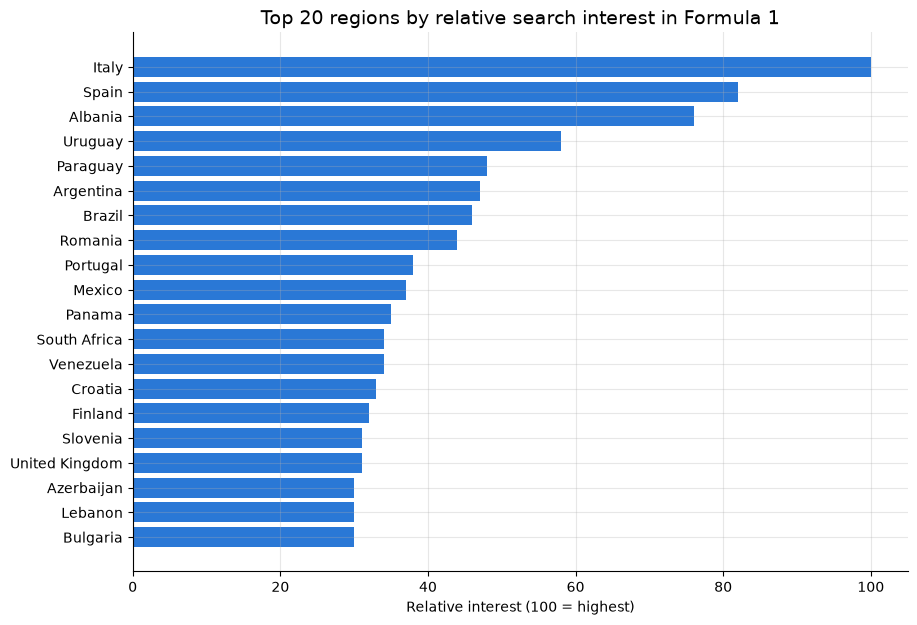

In [5]:
top = regions.head(20).sort_values('Interest')
plt.figure(figsize=(10, 7))
plt.barh(top['Region'], top['Interest'], color='#2a78d6')
plt.title('Top 20 regions by relative search interest in Formula 1')
plt.xlabel('Relative interest (100 = highest)')
plt.show()

Italy tops the list, which fits its long history with Ferrari and Monza. Spain, Albania, Uruguay and Paraguay follow, and much of the top 20 is made up of southern European and Latin American countries. The United Kingdom, home to most of the teams, ranks 16th.

These scores measure Formula 1 searches as a share of all searches in each country, not total volume, which is why smaller countries can rank so highly. The table gives useful context, but the modelling below uses only the worldwide monthly series.

## Creating a date range

In [6]:
dates = pd.date_range(start='2004-01-01', freq='MS', periods=len(data))
dates[0:5]

DatetimeIndex(['2004-01-01', '2004-02-01', '2004-03-01', '2004-04-01',
               '2004-05-01'],
              dtype='datetime64[us]', freq='MS')

In [7]:
data.set_index(dates, inplace=True)
data.drop('Month', axis=1, inplace=True)
data.head()

,Interest
2004-01-01,27
2004-02-01,30
2004-03-01,54
2004-04-01,50
2004-05-01,53


# Exploring the Series

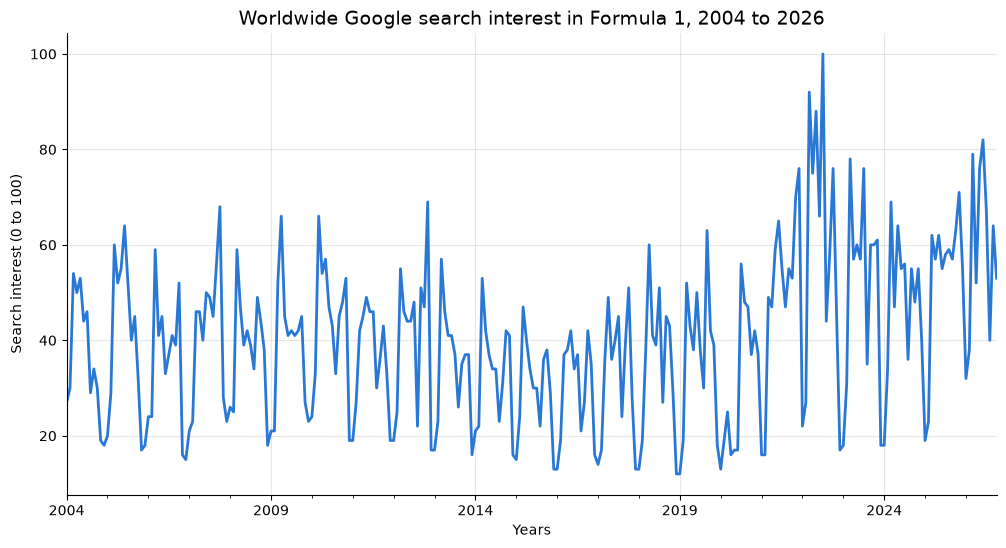

In [8]:
data['Interest'].plot(color='#2a78d6', linewidth=2)
plt.title('Worldwide Google search interest in Formula 1, 2004 to 2026')
plt.xlabel('Years')
plt.ylabel('Search interest (0 to 100)')
plt.show()

The rhythm of the racing calendar is easy to see. Interest jumps in March when the season starts and drops sharply every December and January. The overall level stayed fairly flat from 2004 to about 2019, then rose strongly from 2021.

A few moments stand out. In 2020 the pandemic delayed the season opener until July, so the usual March jump is missing. December 2021 shows an unusual spike, when the championship was decided at the final race in Abu Dhabi. The all-time high of 100 comes in July 2022, during the period when the sport's popularity was growing fastest.

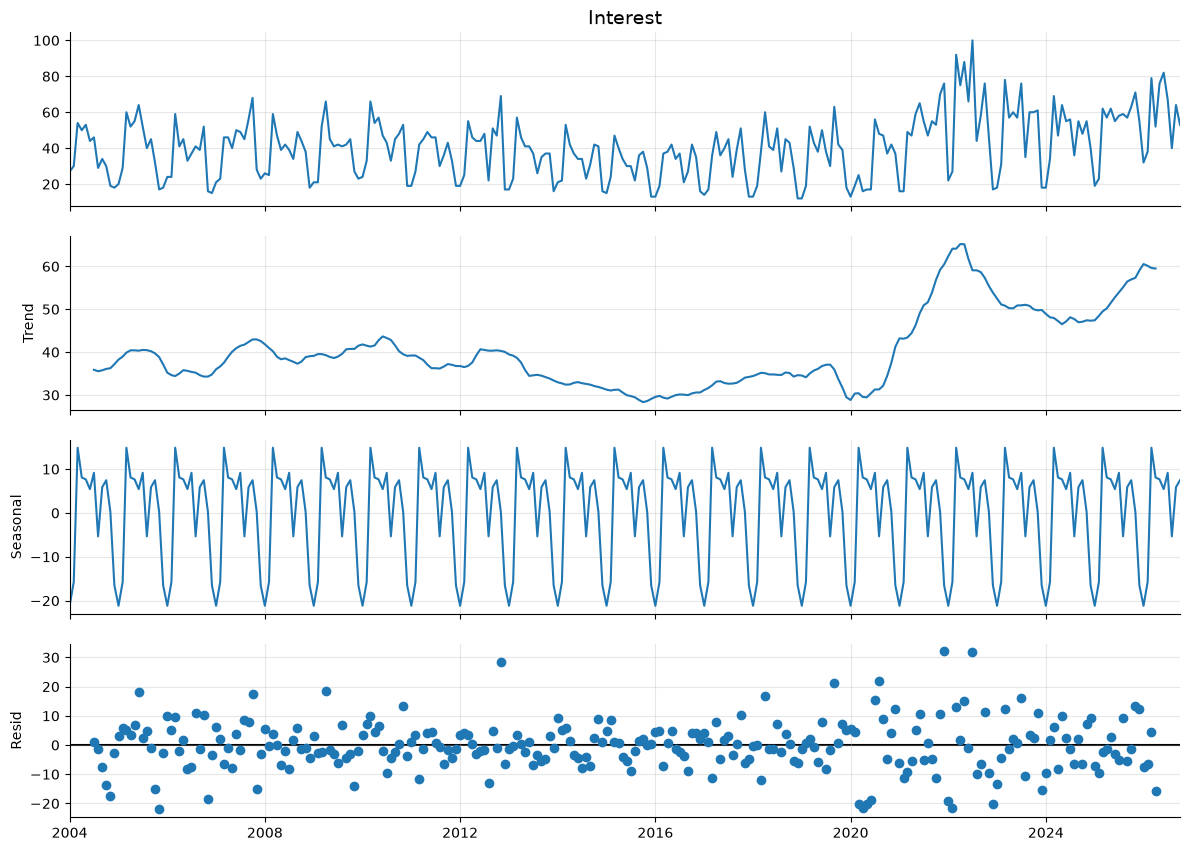

In [9]:
decomposition = seasonal_decompose(data['Interest'], model='additive', period=12)
fig = decomposition.plot()
fig.set_size_inches(12, 9)
plt.show()

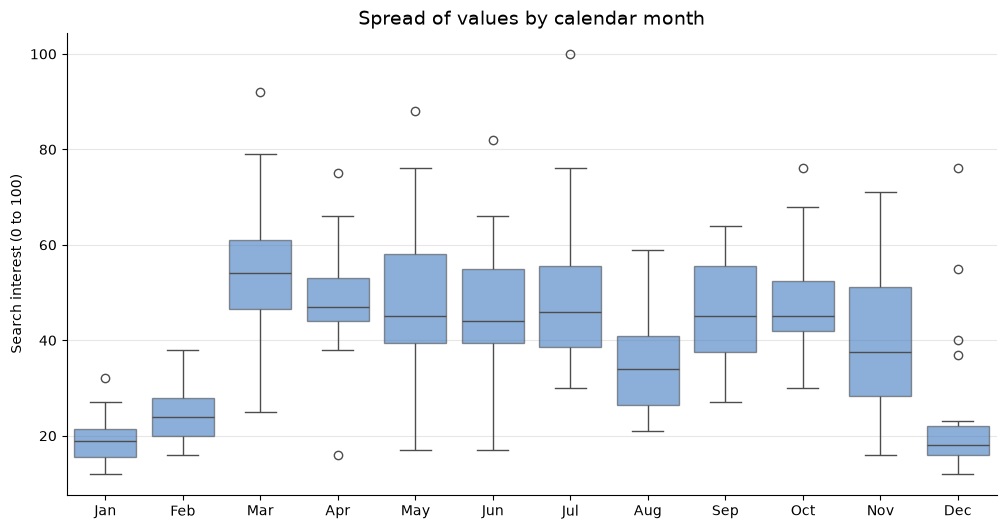

In [10]:
monthly = data.copy()
monthly['Month'] = monthly.index.strftime('%b')
sns.boxplot(x='Month', y='Interest', data=monthly, color='#2a78d6', boxprops={'alpha': 0.6})
plt.title('Spread of values by calendar month')
plt.ylabel('Search interest (0 to 100)')
plt.xlabel('')
plt.show()

The box plot makes the calendar visible. January, February and December are consistently the lowest months, March is the highest, and August dips because of the summer break. November is the most variable month, since it depends on whether the title is still open and when the last race falls. Most of the outliers above the boxes come from 2021 onwards, when interest was unusually high, and the December outliers are years when the season ran into December.

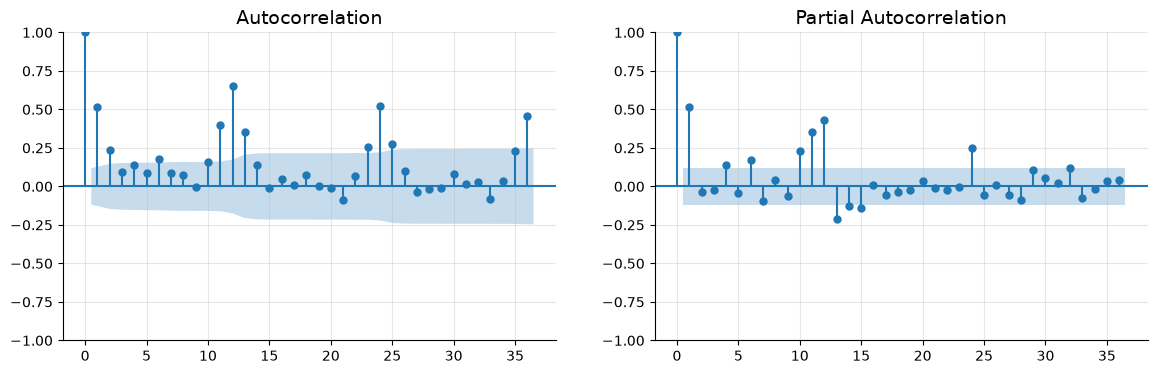

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(data['Interest'], lags=36, ax=axes[0])
plot_pacf(data['Interest'], lags=36, ax=axes[1], method='ywm')
plt.show()

### Stationarity check (Augmented Dickey-Fuller test)

In [12]:
def adf_report(series, name):
    stat, pvalue = adfuller(series.dropna())[:2]
    verdict = 'stationary' if pvalue < 0.05 else 'not stationary'
    print(f"{name:<32} ADF = {stat:7.3f}   p-value = {pvalue:.4f}   -> {verdict}")

adf_report(data['Interest'], 'Original series')
adf_report(data['Interest'].diff(), 'First difference')
adf_report(data['Interest'].diff().diff(12), 'First + seasonal difference')

Original series                  ADF =  -1.556   p-value = 0.5057   -> not stationary
First difference                 ADF =  -5.804   p-value = 0.0000   -> stationary
First + seasonal difference      ADF =  -6.901   p-value = 0.0000   -> stationary


The original series fails the stationarity test (p = 0.51), mostly because of the jump in level after 2021. One difference is enough to make it stationary, so the ARIMA model will use d = 1.

The ACF shows strong peaks at lags 12, 24 and 36. That is the racing calendar repeating every year, and it is a strong sign that seasonal terms will matter.

# Modeling

In [13]:
train = data[data.index < '2024-01-01']
test = data[data.index >= '2024-01-01']
print(f"Train: {train.index[0]:%b %Y} to {train.index[-1]:%b %Y} ({len(train)} months)")
print(f"Test:  {test.index[0]:%b %Y} to {test.index[-1]:%b %Y} ({len(test)} months)")

Train: Jan 2004 to Dec 2023 (240 months)
Test:  Jan 2024 to Oct 2026 (34 months)


The test period runs from January 2024 to October 2026 (34 months). Each model is trained on twenty years of data, 2004 to 2023, and forecasts the whole test period in one step.

# Model 1: Auto Regressive (AR)

An auto regressive model predicts the next value as a weighted sum of the series' own past values (its lags).
Here we use 12 lags so the model can see a full year of history, which gives it a chance to pick up the yearly pattern.

In [14]:
lags = 12
model = AutoReg(train, lags=lags)
model_fit = model.fit()

In [15]:
coefficients = model_fit.params
significant = model_fit.pvalues[model_fit.pvalues < 0.05].index.tolist()

print(f"Lags considered: {lags}")
print(f"Coefficients (beta values):\n{coefficients.round(4)}")
print(f"\nSignificant at the 5% level: {significant}")

Lags considered: 12
Coefficients (beta values):
const           4.3694
Interest.L1     0.3152
Interest.L2    -0.0291
Interest.L3    -0.0005
Interest.L4     0.0871
Interest.L5    -0.0684
Interest.L6     0.1084
Interest.L7    -0.0874
Interest.L8     0.0669
Interest.L9    -0.1417
Interest.L10    0.0274
Interest.L11    0.1474
Interest.L12    0.4742
dtype: float64

Significant at the 5% level: ['Interest.L1', 'Interest.L9', 'Interest.L11', 'Interest.L12']


Lags 1, 9, 11 and 12 are significant, and lag 12 has by far the largest coefficient (0.47). The model has picked up that interest in a given month is best predicted by the same month a year earlier, which is the racing calendar showing through.

In [16]:
predictions = model_fit.predict(start=len(train), end=len(train)+len(test)-1, dynamic=False)
pred_ar = predictions

In [17]:
print(f"First test month ({test.index[0]:%b %Y}): actual = {test['Interest'].iloc[0]:,.0f}, predicted = {predictions.iloc[0]:,.0f}")

First test month (Jan 2024): actual = 18, predicted = 26


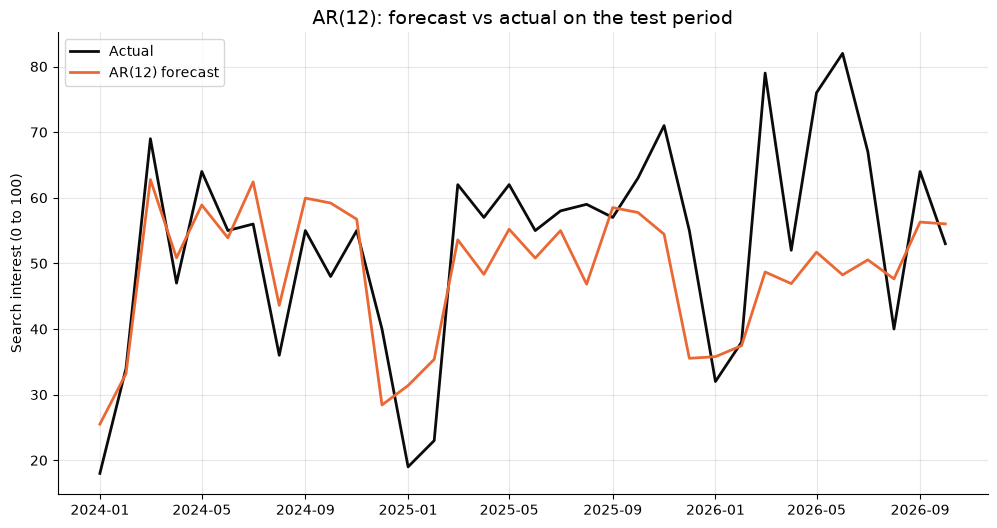

In [18]:
plt.plot(test['Interest'], color='#0b0b0b', linewidth=2, label='Actual')
plt.plot(predictions, color='#eb6834', linewidth=2, label='AR(12) forecast')
plt.title('AR(12): forecast vs actual on the test period')
plt.ylabel('Search interest (0 to 100)')
plt.legend()
plt.show()

In [19]:
rmse = np.sqrt(mean_squared_error(test['Interest'], predictions))
rmse = round(rmse, 3)

abs_error = np.abs(test['Interest'] - predictions)
actual = test['Interest']
mape = np.round(np.mean(abs_error / actual), 3)

resultsDf = pd.DataFrame({'Method': ['Auto Regressive (AR)'], 'RMSE': [rmse], 'MAPE': [mape]})
resultsDf

,Method,RMSE,MAPE
0,Auto Regressive (AR),12.085,0.184


# Model 2: Moving Average (MA)

A moving average model predicts the next value from the series mean plus a weighted sum of recent forecast errors.
We search the MA order q from 0 to 6 and keep the one with the lowest AIC.

In [20]:
best_aic, best_q = np.inf, None
for q in range(0, 7):
    try:
        results = ARIMA(train, order=(0, 0, q)).fit()
        if results.aic < best_aic:
            best_aic, best_q = results.aic, q
    except:
        continue

print(f"Best MA({best_q}) model - AIC: {best_aic:.2f}")

Best MA(2) model - AIC: 1958.93


const      38.6086
ma.L1       0.5368
ma.L2       0.2338
sigma2    198.2774
dtype: float64


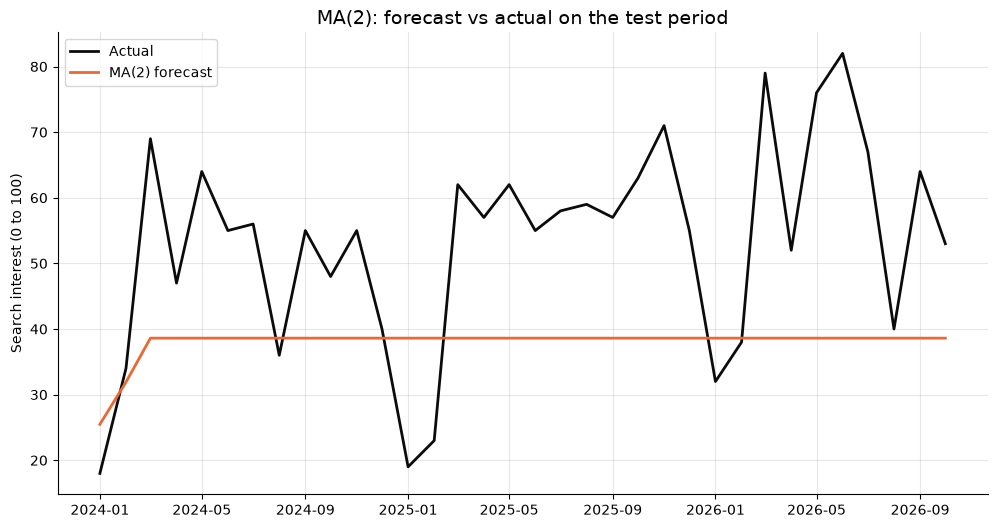

In [21]:
model_fit = ARIMA(train, order=(0, 0, best_q)).fit()
print(model_fit.params.round(4))

predictions = model_fit.predict(start=len(train), end=len(train)+len(test)-1)
pred_ma = predictions

plt.plot(test['Interest'], color='#0b0b0b', linewidth=2, label='Actual')
plt.plot(predictions, color='#eb6834', linewidth=2, label=f'MA({best_q}) forecast')
plt.title(f'MA({best_q}): forecast vs actual on the test period')
plt.ylabel('Search interest (0 to 100)')
plt.legend()
plt.show()

In [22]:
rmse = round(np.sqrt(mean_squared_error(test['Interest'], predictions)), 3)
mape = np.round(np.mean(np.abs(test['Interest'] - predictions) / test['Interest']), 3)

tempResultsDf = pd.DataFrame({'Method': [f'Moving Average MA({best_q})'], 'RMSE': [rmse], 'MAPE': [mape]})
resultsDf = pd.concat([resultsDf, tempResultsDf], ignore_index=True)
resultsDf

,Method,RMSE,MAPE
0,Auto Regressive (AR),12.085,0.184
1,Moving Average MA(2),21.055,0.334


The MA(2) model can only look two months back, so after the second month its forecast flattens at the long-run average of about 39 and stays there. It misses both the seasonal pattern and the higher level of recent years, which leaves it with a MAPE of 33.4%.

# Model 3: Auto Regressive Integrated Moving Average (ARIMA)

ARIMA(p, d, q) combines both ideas and adds differencing: the series is differenced d times to remove the trend, then an AR(p) and an MA(q) part are fitted on what is left.
The value of d is the number of differences the ADF test above needed to make the series stationary, and p and q are searched from 0 to 4 using AIC.

In [23]:
d, series = 0, data['Interest']
while adfuller(series.dropna())[1] > 0.05 and d < 2:
    series = series.diff()
    d += 1
print(f"Differencing order from the ADF test: d = {d}")

pq = list(itertools.product(range(0, 5), range(0, 5)))
best_aic, best_pdq = np.inf, None
for p, q in pq:
    try:
        results = ARIMA(train, order=(p, d, q)).fit()
        if results.aic < best_aic:
            best_aic, best_pdq = results.aic, (p, d, q)
    except:
        continue

print(f"Best ARIMA{best_pdq} model - AIC: {best_aic:.2f}")

Differencing order from the ADF test: d = 1


Best ARIMA(4, 1, 4) model - AIC: 1933.21


ar.L1      -0.4146
ar.L2      -0.4167
ar.L3      -0.4247
ar.L4       0.5774
ma.L1      -0.0306
ma.L2      -0.0114
ma.L3       0.0290
ma.L4      -0.9869
sigma2    166.0418
dtype: float64


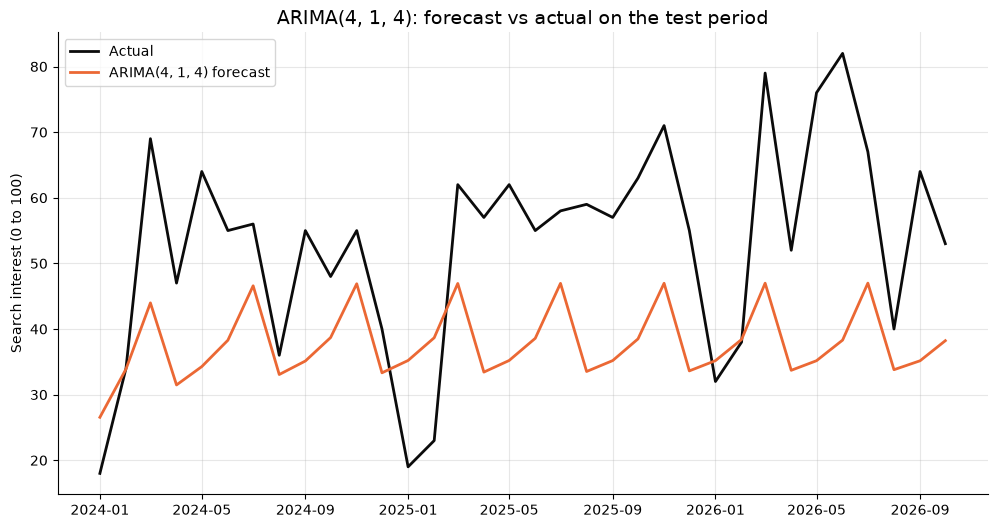

In [24]:
model_fit = ARIMA(train, order=best_pdq).fit()
print(model_fit.params.round(4))

predictions = model_fit.predict(start=len(train), end=len(train)+len(test)-1)
pred_arima = predictions

plt.plot(test['Interest'], color='#0b0b0b', linewidth=2, label='Actual')
plt.plot(predictions, color='#eb6834', linewidth=2, label=f'ARIMA{best_pdq} forecast')
plt.title(f'ARIMA{best_pdq}: forecast vs actual on the test period')
plt.ylabel('Search interest (0 to 100)')
plt.legend()
plt.show()

In [25]:
rmse = round(np.sqrt(mean_squared_error(test['Interest'], predictions)), 3)
mape = np.round(np.mean(np.abs(test['Interest'] - predictions) / test['Interest']), 3)

tempResultsDf = pd.DataFrame({'Method': [f'ARIMA{best_pdq}'], 'RMSE': [rmse], 'MAPE': [mape]})
resultsDf = pd.concat([resultsDf, tempResultsDf], ignore_index=True)
resultsDf

,Method,RMSE,MAPE
0,Auto Regressive (AR),12.085,0.184
1,Moving Average MA(2),21.055,0.334
2,"ARIMA(4, 1, 4)",20.569,0.330


With d = 1, the search chose ARIMA(4, 1, 4). Like the MA model, it struggles. The last training value is December 2023, a winter low of 18, so the forecast starts from that low point. Its AR and MA terms then produce a regular wave, but one that stays between about 33 and 47, well below the actual level of recent seasons. Its MAPE (33.0%) is barely better than the MA model.

# Model 4: Seasonal Auto Regressive Integrated Moving Average (SARIMA)

SARIMA extends ARIMA with a second set of AR, differencing and MA terms that work at the seasonal lag, here 12 months.
This lets the model learn that each month tends to resemble the same month a year earlier. As in the original notebook, every combination of (p, d, q) and seasonal (P, D, Q) between 0 and 1 is tried and the lowest AIC wins.

In [26]:
p = d = q = range(0, 2)
pdq = list(itertools.product(p, d, q))
seasonal_pdq = [(x[0], x[1], x[2], 12) for x in pdq]

best_aic, best_pdq, best_seasonal_pdq = np.inf, None, None
for param in pdq:
    for param_seasonal in seasonal_pdq:
        try:
            results = SARIMAX(train, order=param, seasonal_order=param_seasonal,
                              enforce_invertibility=False, enforce_stationarity=False).fit(disp=False)
            if results.aic < best_aic:
                best_aic, best_pdq, best_seasonal_pdq = results.aic, param, param_seasonal
        except:
            continue

print(f"Best SARIMA{best_pdq} x {best_seasonal_pdq} model - AIC: {best_aic:.2f}")

Best SARIMA(1, 1, 1) x (0, 1, 1, 12) model - AIC: 1618.91


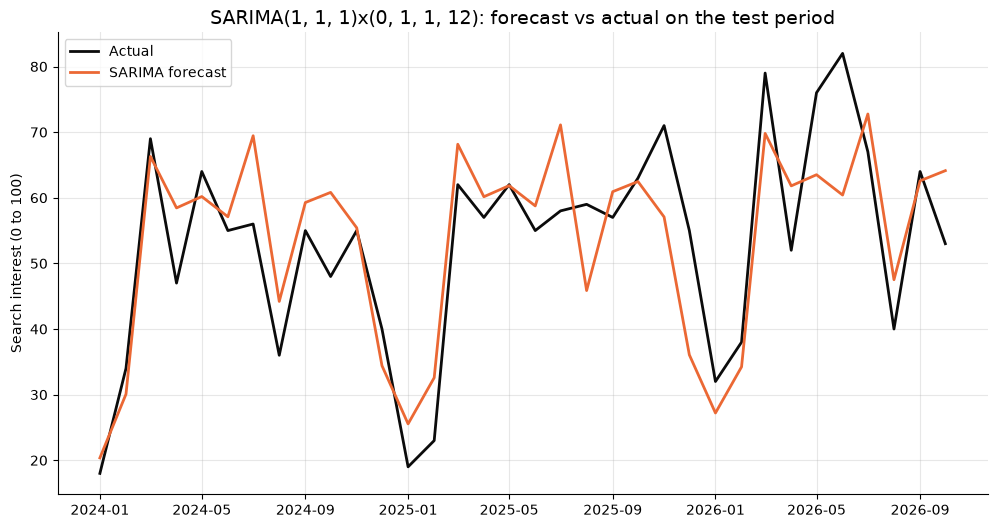

In [27]:
model = SARIMAX(train, order=best_pdq, seasonal_order=best_seasonal_pdq,
                enforce_invertibility=False, enforce_stationarity=False)
model_fit = model.fit(disp=False)

predictions = model_fit.predict(start=len(train), end=len(train)+len(test)-1, dynamic=False)
pred_sarima = predictions

plt.plot(test['Interest'], color='#0b0b0b', linewidth=2, label='Actual')
plt.plot(predictions, color='#eb6834', linewidth=2, label='SARIMA forecast')
plt.title(f'SARIMA{best_pdq}x{best_seasonal_pdq}: forecast vs actual on the test period')
plt.ylabel('Search interest (0 to 100)')
plt.legend()
plt.show()

In [28]:
rmse = round(np.sqrt(mean_squared_error(test['Interest'], predictions)), 3)
mape = np.round(np.mean(np.abs(test['Interest'] - predictions) / test['Interest']), 3)

tempResultsDf = pd.DataFrame({'Method': [f'SARIMA{best_pdq}x{best_seasonal_pdq}'], 'RMSE': [rmse], 'MAPE': [mape]})
resultsDf = pd.concat([resultsDf, tempResultsDf], ignore_index=True)
resultsDf

,Method,RMSE,MAPE
0,Auto Regressive (AR),12.085,0.184
1,Moving Average MA(2),21.055,0.334
2,"ARIMA(4, 1, 4)",20.569,0.330
3,"SARIMA(1, 1, 1)x(0, 1, 1, 12)",9.084,0.151


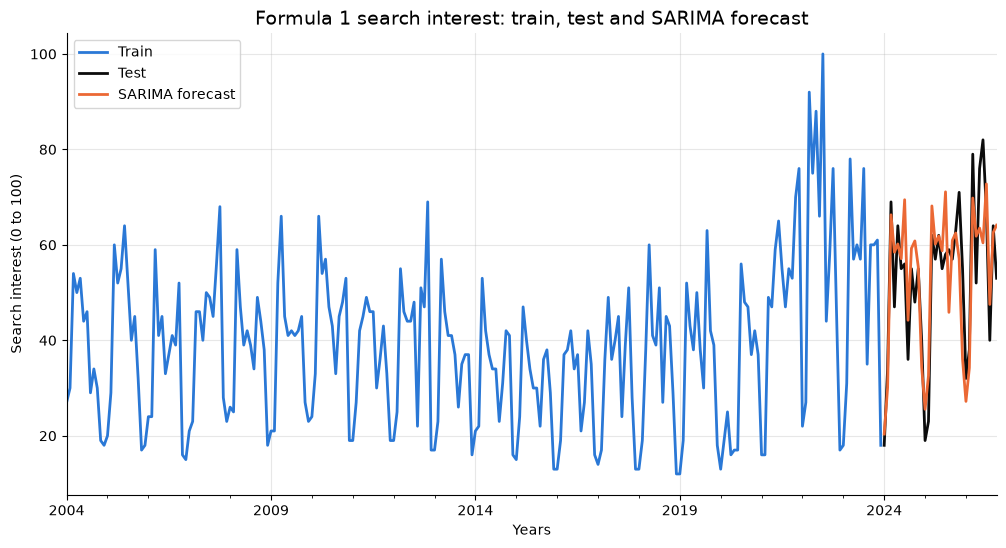

In [29]:
axis = train['Interest'].plot(label='Train', color='#2a78d6', linewidth=2)
test['Interest'].plot(ax=axis, label='Test', color='#0b0b0b', linewidth=2)
predictions.plot(ax=axis, label='SARIMA forecast', color='#eb6834', linewidth=2)
axis.set_xlabel('Years')
axis.set_ylabel('Search interest (0 to 100)')
axis.set_title('Formula 1 search interest: train, test and SARIMA forecast')
plt.legend(loc='best')
plt.show()

The best model is SARIMA(1, 1, 1) x (0, 1, 1, 12). It follows the racing calendar closely, with a jump each March, a dip each August and a winter low each December and January.

Most of its remaining error comes from things a calendar cannot predict. It underestimates the end of the 2025 season, when interest stayed unusually high through November and December, and it falls short of the strong mid-season months of 2026.

# Comparing the Models

In [30]:
resultsDf['MAPE (%)'] = (resultsDf['MAPE'] * 100).round(1)
resultsDf.sort_values('RMSE')

,Method,RMSE,MAPE,MAPE (%)
3,"SARIMA(1, 1, 1)x(0, 1, 1, 12)",9.084,0.151,15.1
0,Auto Regressive (AR),12.085,0.184,18.4
2,"ARIMA(4, 1, 4)",20.569,0.330,33.0
1,Moving Average MA(2),21.055,0.334,33.4


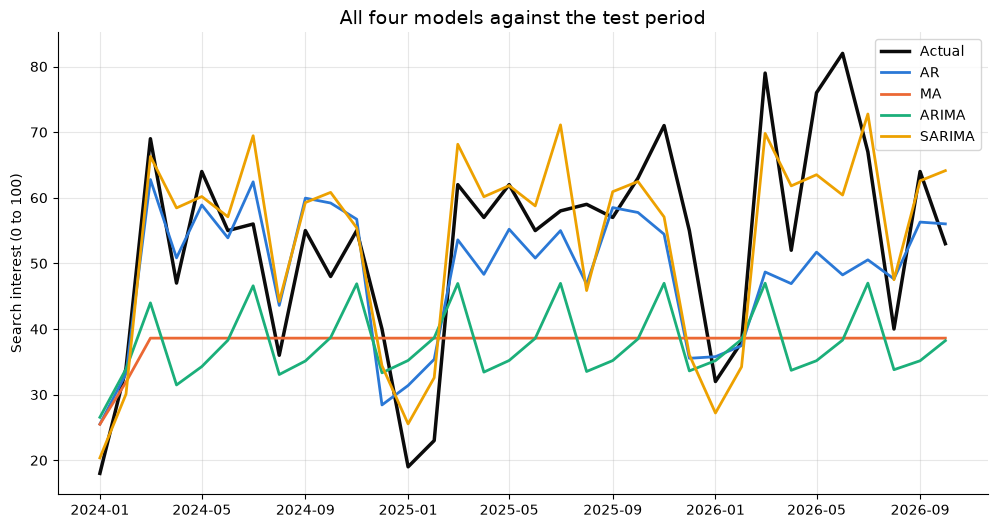

In [31]:
plt.plot(test['Interest'], color='#0b0b0b', linewidth=2.5, label='Actual')
for name, pred, colour in [('AR', pred_ar, '#2a78d6'), ('MA', pred_ma, '#eb6834'),
                           ('ARIMA', pred_arima, '#1baf7a'), ('SARIMA', pred_sarima, '#eda100')]:
    plt.plot(pred, color=colour, linewidth=2, label=name)
plt.title('All four models against the test period')
plt.ylabel('Search interest (0 to 100)')
plt.legend()
plt.show()

# Conclusion

**SARIMA gives the best forecast of Formula 1 search interest**, with an RMSE of 9.1 points on the 0 to 100 scale.

| Rank | Model | RMSE | MAPE |
|---|---|---|---|
| 1 | SARIMA(1,1,1)x(0,1,1,12) | 9.1 | 15.1% |
| 2 | AR(12) | 12.1 | 18.4% |
| 3 | ARIMA(4,1,4) | 20.6 | 33.0% |
| 4 | MA(2) | 21.1 | 33.4% |

The MAPE values are higher than for the airline or milk data, but part of that comes from the measure itself. In winter, interest drops to around 20, so a miss of 7 points is already a 35% error. RMSE is the fairer comparison here, and on that measure SARIMA is clearly ahead.

The AR model does well as the runner-up because its lag-12 term captures the season calendar. ARIMA and MA, which have no seasonal memory, are left forecasting a flat or slowly waving line around the long-run average.

What makes this dataset interesting is that interest in a sport is shaped by events as well as the calendar. A close title race, a delayed season or a popular documentary series can all move the numbers in ways the past does not predict. SARIMA captures the calendar very well, and the gaps that remain are mostly those kinds of events.